# DBSCAN

Density-based clustering. No `k` to choose, finds arbitrarily shaped clusters, and labels outliers as noise (`-1`).

- A point is a **core point** if at least `min_samples` points (itself included) lie within distance `eps`.
- A cluster starts at an unvisited core point and grows through every core point reachable from it. **Border points** (within `eps` of a core point, but not core themselves) join the cluster without extending it.
- Anything left over is **noise**.

Compared to K-Means (`27_kmeans`): handles non-convex shapes such as two moons, and needs no cluster count — but `eps` must suit the data's scale.

Uses a full pairwise distance matrix (O(n²) memory), fine for the sizes this repo targets.

## Usage

```python
# (the class is defined in the Implementation section below)

labels = DBSCAN(eps=0.2, min_samples=5).fit_predict(X)   # -1 = noise
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class DBSCAN:
    """Density-based clustering. labels_ holds cluster ids 0..k-1; noise points get -1.

    ponytail: full n x n distance matrix, O(n^2) memory. Use a KD-tree for large n."""

    def __init__(self, eps=0.5, min_samples=5):
        self.eps = eps
        self.min_samples = min_samples
        self.labels_ = None
        self.core_sample_indices_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n = len(X)
        dist = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
        neighbors = [np.flatnonzero(row <= self.eps) for row in dist]  # includes the point itself
        is_core = np.array([len(nb) >= self.min_samples for nb in neighbors])

        labels = np.full(n, -1)
        cluster = 0
        for i in range(n):
            if labels[i] != -1 or not is_core[i]:
                continue
            labels[i] = cluster
            stack = [i]
            while stack:  # grow the cluster through chains of core points
                j = stack.pop()
                if not is_core[j]:
                    continue  # border points join the cluster but do not extend it
                for k in neighbors[j]:
                    if labels[k] == -1:
                        labels[k] = cluster
                        stack.append(k)
            cluster += 1

        self.labels_ = labels
        self.core_sample_indices_ = np.flatnonzero(is_core)
        return self

    def fit_predict(self, X):
        return self.fit(X).labels_

## See it work

### 1. Core, border and noise points

DBSCAN grows clusters from **core points** (at least `min_samples` points within distance `eps`). Points within `eps` of a core point but not core themselves are **border** points. Everything else is **noise** (label `−1`). Clusters can have any shape, and outliers are labelled, not forced into a cluster.

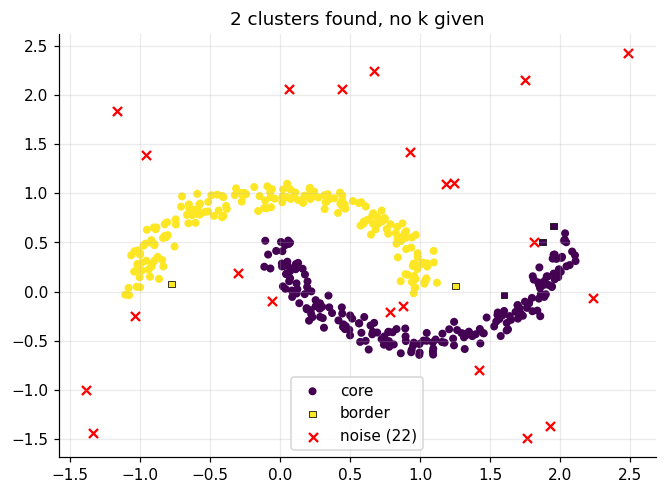

In [3]:
from sklearn.datasets import make_moons

rng = np.random.default_rng(0)
X, _ = make_moons(n_samples=400, noise=0.07, random_state=42)
X = np.vstack([X, rng.uniform(-1.5, 2.5, size=(25, 2))])            # sprinkle in 25 random noise points
m = DBSCAN(eps=0.15, min_samples=5).fit(X)
core = np.zeros(len(X), bool); core[m.core_sample_indices_] = True
noise = m.labels_ == -1
plt.figure(figsize=(7, 5))
plt.scatter(*X[~noise & core].T, c=m.labels_[~noise & core], cmap="viridis", s=18, label="core")
plt.scatter(*X[~noise & ~core].T, c=m.labels_[~noise & ~core], cmap="viridis", s=18, marker="s", edgecolor="k", linewidth=0.5, label="border")
plt.scatter(*X[noise].T, c="red", marker="x", s=35, label=f"noise ({noise.sum()})"); plt.legend(); plt.title(f"{len(set(m.labels_) - {-1})} clusters found, no k given"); plt.show()

### 2. Choosing `eps`: the k-distance plot

For each point compute the distance to its `min_samples`-th nearest neighbour and sort them. Points in clusters have small values; noise has large ones. The **knee** of the curve is a good `eps`. Then see what happens for `eps` too small (everything is noise) or too large (clusters merge).

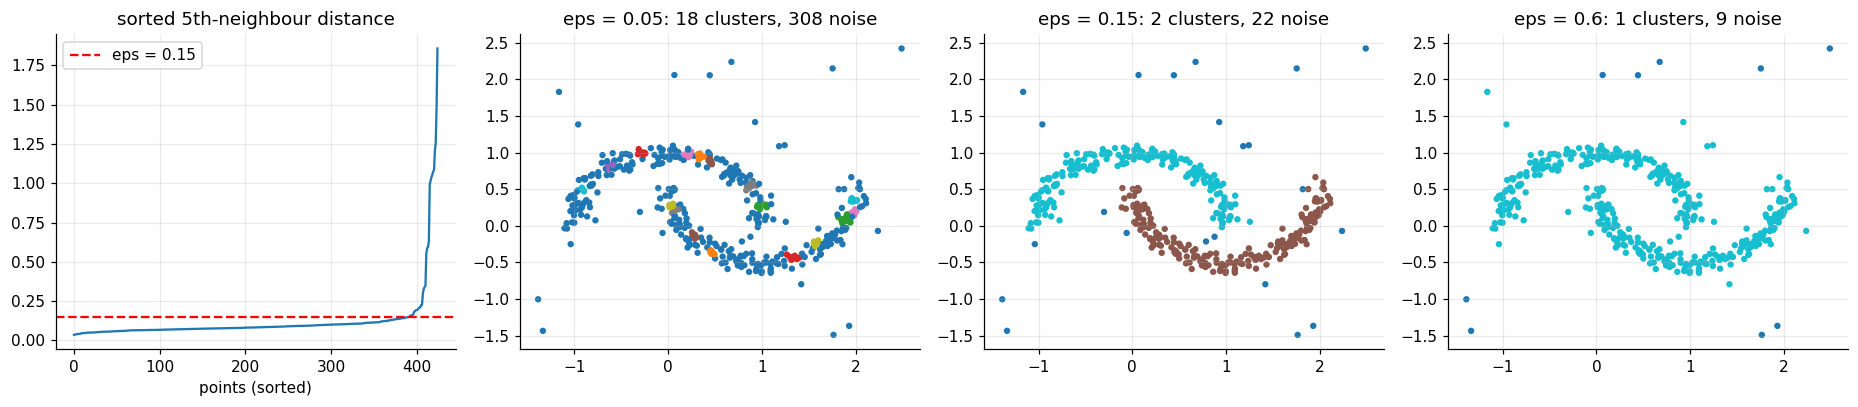

In [4]:
D = np.sqrt(((X[:, None] - X[None]) ** 2).sum(-1)); kdist = np.sort(np.sort(D, axis=1)[:, 5])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
axes[0].plot(kdist); axes[0].axhline(0.15, color="r", ls="--", label="eps = 0.15"); axes[0].set(title="sorted 5th-neighbour distance", xlabel="points (sorted)"); axes[0].legend()
for ax, eps in zip(axes[1:], [0.05, 0.15, 0.6]):
    mm = DBSCAN(eps=eps, min_samples=5).fit(X)
    ax.scatter(*X.T, c=mm.labels_, cmap="tab10", s=10); ax.set_title(f"eps = {eps}: {len(set(mm.labels_) - {-1})} clusters, {(mm.labels_ == -1).sum()} noise")
plt.tight_layout(); plt.show()

### 3. Different densities are DBSCAN's weak spot

One global `eps` cannot suit a tight cluster and a sparse one at once: the value that isolates the tight one turns the sparse one into noise.

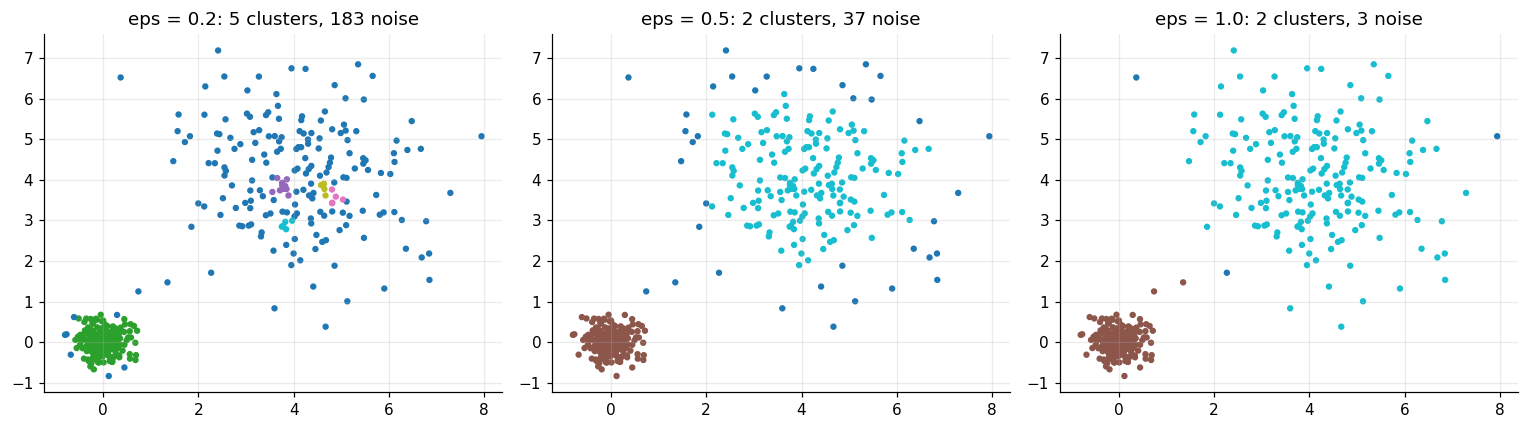

In [5]:
from sklearn.datasets import make_blobs
Xd = np.vstack([make_blobs(n_samples=200, centers=[[0, 0]], cluster_std=0.3, random_state=0)[0], make_blobs(n_samples=200, centers=[[4, 4]], cluster_std=1.3, random_state=1)[0]])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, eps in zip(axes, [0.2, 0.5, 1.0]):
    mm = DBSCAN(eps=eps, min_samples=5).fit(Xd); ax.scatter(*Xd.T, c=mm.labels_, cmap="tab10", s=10); ax.set_title(f"eps = {eps}: {len(set(mm.labels_) - {-1})} clusters, {(mm.labels_ == -1).sum()} noise")
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.cluster import DBSCAN as SklearnDBSCAN
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score

X, _ = make_moons(n_samples=400, noise=0.07, random_state=42)

ours = DBSCAN(eps=0.15, min_samples=5).fit(X)
theirs = SklearnDBSCAN(eps=0.15, min_samples=5).fit(X)

ari = adjusted_rand_score(ours.labels_, theirs.labels_)
print("clusters: ours=%d sklearn=%d" % (len(set(ours.labels_) - {-1}), len(set(theirs.labels_) - {-1})))
print("noise points: ours=%d sklearn=%d" % ((ours.labels_ == -1).sum(), (theirs.labels_ == -1).sum()))
print("agreement with sklearn (adjusted rand index): %.4f" % ari)
assert np.array_equal(ours.core_sample_indices_, theirs.core_sample_indices_)
assert ari > 0.99

clusters: ours=2 sklearn=2
noise points: ours=3 sklearn=3
agreement with sklearn (adjusted rand index): 1.0000


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_two_blobs_and_an_outlier():
    rng = np.random.default_rng(0)
    X = np.vstack([rng.normal(0, 0.3, (40, 2)), rng.normal(5, 0.3, (40, 2)), [[20.0, 20.0]]])
    labels = DBSCAN(eps=0.8, min_samples=5).fit_predict(X)

    assert labels[-1] == -1  # the far point is noise
    assert len(set(labels[:40])) == 1 and len(set(labels[40:80])) == 1
    assert labels[0] != labels[40]
    assert set(labels) == {-1, 0, 1}


def test_separates_two_moons_which_kmeans_cannot():
    from sklearn.datasets import make_moons

    X, y = make_moons(n_samples=300, noise=0.05, random_state=0)
    labels = DBSCAN(eps=0.2, min_samples=5).fit_predict(X)
    clusters = [c for c in set(labels) if c != -1]
    assert len(clusters) == 2
    # each moon should be (almost) a single cluster
    for moon in (0, 1):
        counts = np.bincount(labels[y == moon][labels[y == moon] != -1])
        assert counts.max() / (y == moon).sum() > 0.95


def test_all_noise_when_min_samples_too_high():
    X = np.arange(10.0).reshape(-1, 1)
    assert (DBSCAN(eps=0.5, min_samples=3).fit_predict(X) == -1).all()

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_two_blobs_and_an_outlier
PASS test_separates_two_moons_which_kmeans_cannot
PASS test_all_noise_when_min_samples_too_high

all 3 tests passed


## Takeaways

- **Use it** for arbitrary-shaped clusters, spatial data, and when you need outliers labelled as noise rather than assigned somewhere. No `k` needed.
- **Parameters:** `eps` (neighbourhood radius, the sensitive one; use the k-distance plot) and `min_samples` (about `2·d` is a common start).
- **Pitfalls:** one global density (section 3; see HDBSCAN/OPTICS), distance loses meaning in high dimensions, and border points can be assigned to either neighbouring cluster (order dependent).
- **Interview line:** *"Density-connected components: core points have ≥ `min_samples` neighbours within `eps`; clusters are chains of core points plus their borders; the rest is noise."*